## 1. Data Understanding

### 1.1 Dataset Description

The SECOM dataset contains measurements collected
from a semiconductor manufacturing process.

The objective is to investigate whether manufacturing
measurements can help predict product quality failures.

- Features: 590
- Observations: 1568
- Overall missing value percentage: 4.54% of all data values
- 538 features out of totl 590 have atleast one missing value
- 41951 data values are missing across 538 features
- No duplicates found at row level

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np

# Dataset paths
DATA_DIR = Path("../secom_data/raw")

data_path = DATA_DIR / "secom.data"
labels_path = DATA_DIR / "secom_labels.data"

# Load data
X_raw = pd.read_csv(data_path, delimiter="\s+", header=None)
y_raw = pd.read_csv(labels_path, delimiter="\s+", header=None)

y = y_raw.iloc[:,0]

print("Feature dimensions:", X_raw.shape)
print("Target dimensions:", y.shape)

print("Number of observations:", X_raw.shape[0])
print("Number of features:", X_raw.shape[1])

# Missing values per feature
missing_values = X_raw.isnull().sum()

# Total missing values
print(missing_values.sum())

# Features containing missing values
print(
    "Features with missing values:",
    (missing_values > 0).sum()
)

# Percentage of missing values
missing_percentage = (
    X_raw.isnull().sum().sum()*100/ X_raw.size
)

print("Missing value percentage:",missing_percentage)
print("Duplicate rows:", X_raw.duplicated().sum())

Feature dimensions: (1567, 590)
Target dimensions: (1567,)
Number of observations: 1567
Number of features: 590
41951
Features with missing values: 538
Missing value percentage: 4.537548808583821
Duplicate rows: 0


In [ ]:
### 1.2 Understand the missing value percentage for features

In [13]:
missing_summary = pd.DataFrame({
    "missing_count": X_raw.isnull().sum(),
    "missing_percentage": X_raw.isnull().mean() * 100
})

# Sort features from highest to lowest missing percentage
missing_summary = missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)


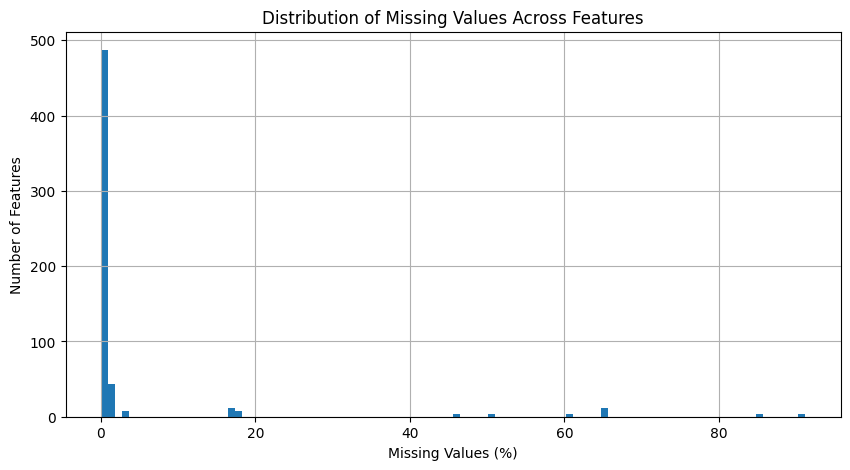

In [16]:
import matplotlib.pyplot as plt

missing_summary["missing_percentage"].plot(
    kind="hist",
    bins=100,
    grid=True,
    figsize=(10, 5)
)

plt.title("Distribution of Missing Values Across Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Number of Features")
plt.show()